# GSB 5544 — Topic 9.2: Model Evaluation and Cross-Validation — SOLUTION
*Which model should we trust? Training error flatters every model; validation error and K-fold cross-validation
tell the truth. Watch each step on the animation page, then reproduce it in scikit-learn.*

## The plan

Topic 9.1 gave us three models that all answer "what will this house sell for?" with the same four lines of
code. Today's question is different: **how good is each answer, and which model should we pick?**

| | | tools |
|---|---|---|
| **1. Three models, one recipe** (review) | what each `.fit()` learns, what each `.predict()` does | `LinearRegression`, `KNeighborsRegressor`, `DecisionTreeRegressor` |
| **2. Decision trees, a closer look** | splits, nodes, leaves, depth | `plot_tree`, `max_depth`, `decision_path` |
| **3. Training, validation and test data** | three jobs for three sets of rows | `train_test_split` |
| **4. Training error vs validation error** | why training error alone is not enough | `root_mean_squared_error` |
| **5. K-fold cross-validation, step by step** | cut, hold out, fit, score, repeat, average | `KFold`, `.split()` |
| **6. One call** | the loop packaged | `cross_val_score`, `cross_validate`, `scoring=` |
| **7. Choosing a model and its settings** | compare candidates on CV; test once, at the end | a loop over `k` and `max_depth` |
| **8. Pipelines and leakage** | preprocessing *inside* every fold | `make_pipeline`, `StandardScaler` |
| **9. Review questions** | | |

📖 **Pre-class reading:** *Estimating the Test Error* (`GSB_5544_Topic_9_2b_Cross_Validation.ipynb`) — validation error, two-fold and then
K-fold cross-validation on the Bordeaux wines with `cross_val_score(scoring="neg_mean_squared_error")`. This
notebook uses the same wines and the same ideas, and adds: the eight-house animation, `KFold` with shuffling
written out as a loop, `scoring="neg_root_mean_squared_error"`, training scores from `cross_validate`, model
selection with a sealed test set, and pipelines.

🎬 **The animation page:** [https://gato365.github.io/gsb5544_instructor_learn_prep/week_9/algorithms.html](https://gato365.github.io/gsb5544_instructor_learn_prep/week_9/algorithms.html). Its new **Cross-validation in motion** section
([#cv](https://gato365.github.io/gsb5544_instructor_learn_prep/week_9/algorithms.html#cv)) uses the same eight houses as sections 1–6 below and shows every fold, every refit and
every error; **What every number means** ([#numbers](https://gato365.github.io/gsb5544_instructor_learn_prep/week_9/algorithms.html#numbers)) defines each quantity on the page.

**Rhythm for each section:** open the 🎬 link and watch → *predict* the number the notebook is about to print →
run the cell → compare with the page.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.metrics import root_mean_squared_error
from sklearn.model_selection import train_test_split, KFold, cross_val_score, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

---
## 1. Three models, one recipe (review)

The same eight houses as Topic 9.1 and the animation page: **size** in hundreds of square feet, **price**
in thousands of dollars. This is a **regression** task — the target is a number — so errors are measured in
dollars (RMSE), not in "percent correct".

The recipe never changes: `model = Model(...)` → `model.fit(X, y)` → `model.predict(X_new)`. What changes
is what happens *inside* those calls:

| model | `Model(...)` | what `.fit(X, y)` learns | what `.predict(x)` does | shape |
|---|---|---|---|---|
| linear regression | `LinearRegression()` — no settings | an intercept and a slope, by least squares | intercept + slope × size | a line |
| k-nearest neighbors | `KNeighborsRegressor(n_neighbors=k)` — *k* is chosen by you | nothing; it stores the rows | finds the *k* closest training sizes, averages their prices | a staircase of local averages |
| decision tree | `DecisionTreeRegressor(max_depth=d)` — *d* is chosen by you | thresholds ("size ≤ 22?") that minimize SSE, and each leaf's mean | answers the questions down to a leaf, reports the leaf mean | a staircase with one value per leaf |

Settings you choose before fitting (`n_neighbors`, `max_depth`) are **hyperparameters**; numbers `.fit()`
produces (`intercept_`, `coef_`, the thresholds) are **parameters**. Choosing hyperparameters well is the
subject of sections 5–7.

In [2]:
houses = pd.DataFrame({
    "size":  [10, 12, 15, 18, 20, 24, 28, 32],         # hundreds of square feet
    "price": [150, 180, 200, 260, 250, 320, 360, 410], # thousands of dollars
})
X = houses[["size"]]           # features: a DataFrame (double brackets)
y = houses["price"]            # target: a Series
new = pd.DataFrame({"size": [22.5]})

models = {
    "linear regression":   LinearRegression(),
    "3-nearest neighbors": KNeighborsRegressor(n_neighbors=3),
    "tree, max_depth=2":   DecisionTreeRegressor(max_depth=2),
}
for name, model in models.items():
    model.fit(X, y)
    pred = model.predict(new)[0]
    rmse_train = root_mean_squared_error(y, model.predict(X))
    print(f"{name:20s} predicts {pred:7.2f} for size 22.5    training RMSE = {rmse_train:5.2f}")

linear regression    predicts  297.02 for size 22.5    training RMSE =  9.45
3-nearest neighbors  predicts  276.67 for size 22.5    training RMSE = 23.57
tree, max_depth=2    predicts  340.00 for size 22.5    training RMSE = 16.27


`root_mean_squared_error(y_true, y_pred)` is the error you will see everywhere today: square each error
(actual − predicted), average, take the square root. It is in the units of the target, here **thousands of
dollars**, which makes "the model is off by about 9 thousand dollars" a sentence you can say out loud.

Here it is computed on the **same eight houses the models were fitted on**, so it is a *training* RMSE.
Keep that phrase in mind; section 4 is about why it flatters.

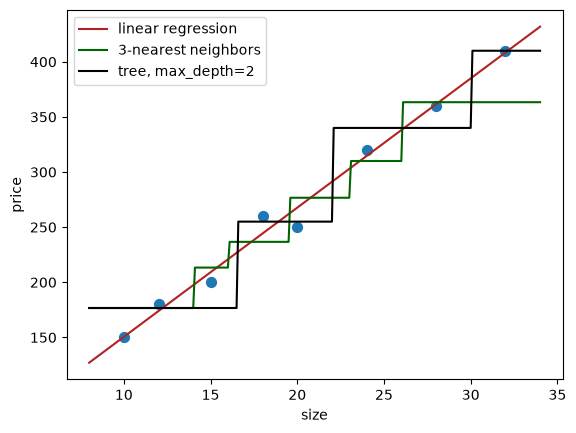

In [3]:
sizes = pd.DataFrame({"size": np.linspace(8, 34, 261)})
ax = houses.plot.scatter(x="size", y="price", s=50)
for (name, model), color in zip(models.items(), ["firebrick", "darkgreen", "black"]):
    ax.plot(sizes["size"], model.predict(sizes), color=color, label=name)
ax.legend();

✅ **Checkpoint 1.** (a) In the loop, which single line is different for the three models, and which lines are
identical? (b) Rank the three models by training RMSE. Which ranking would you expect for *new* houses, and
why is that a different question? (c) Which of the numbers 3, 2, 33.29 and 11.72 are hyperparameters and
which are parameters?

**Answer:** (a) Only the `Model(...)` line in the dictionary differs (and its import). `fit`, `predict` and
`root_mean_squared_error` are the same for all three — that is the point of scikit-learn's common interface.
(b) By training RMSE: the line **9.45** (best), the depth-2 tree **16.27**, 3-NN **23.57**. The line wins here
because these eight prices are nearly linear in size. But training RMSE only says how well each model
reproduces houses it has already seen; a model can score 0 on that (1-NN, or a tree with one house per leaf)
and still predict new houses badly. How well it predicts *unseen* houses is a different question — the one
sections 4–7 answer. (c) 3 (`n_neighbors`) and 2
(`max_depth`) are hyperparameters: chosen before fitting. 33.29 (`intercept_`) and 11.72 (`coef_`) are
parameters: produced by `.fit()`.

---
## 2. Decision trees, a closer look

A tree is the model students find easiest to *read* and hardest to *trust*, so it deserves a second look.

**How a split is selected.** At a node, scikit-learn considers the question "size ≤ t?" for every midpoint *t*
between neighboring training sizes. Each candidate splits the node's houses into a left group (≤ t) and a
right group (> t). The candidate's score is the **SSE** — the sum of squared gaps between each house's price
and *its own group's* mean, left group plus right group. The smallest SSE wins. (In Topic 9.1 you computed
this table by hand; the animation page lists all seven candidates.)

**What the boxes mean.** `plot_tree` prints three numbers in every node:

| printed | meaning | relation |
|---|---|---|
| `samples` | how many training houses reach the node | the two children's samples add up to the parent's |
| `value` | the mean price of those houses — the prediction if this node were a leaf | |
| `squared_error` | the mean squared gap between those prices and `value` | = SSE ÷ samples; 0 means all prices equal |

**Branches** are the yes/no answers (left = yes = "≤"), **leaves** are nodes with no question. **Predicting**
means following the answers for a new house down to a leaf and reporting the leaf's `value`.

🎬 *Watch it on the page:* [Decision tree: split, then split again (max_depth = 2)](https://gato365.github.io/gsb5544_instructor_learn_prep/week_9/algorithms.html#decision-tree&depth=2) — press **Play**, or step through with → and ←.

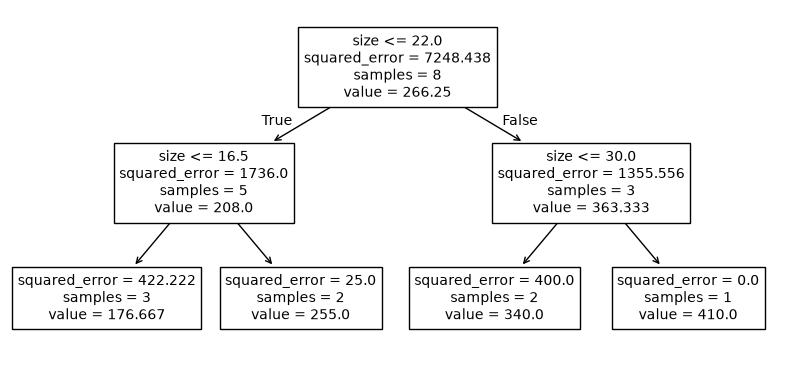

In [4]:
tree2 = DecisionTreeRegressor(max_depth=2).fit(X, y)
plt.figure(figsize=(10, 4.5))
plot_tree(tree2, feature_names=["size"], fontsize=10);

Check the root box against the formulas: `samples = 8`, `value` = mean of the eight prices, and
`squared_error` × 8 should equal the SSE of the prices around their mean.

In [5]:
root_sse = ((y - y.mean()) ** 2).sum()
print("value (mean price):", y.mean())
print("SSE around the mean:", root_sse, "   squared_error = SSE / 8 =", round(root_sse / 8, 2))

value (mean price): 266.25
SSE around the mean: 57987.5    squared_error = SSE / 8 = 7248.44


**Following one house through the tree.** `decision_path` returns the nodes the new house visits; the tree's
internal arrays (`tree_.feature`, `tree_.threshold`, `tree_.value`, `tree_.n_node_samples`) let us print the
question asked at each one.

In [6]:
t = tree2.tree_
path = tree2.decision_path(new).indices           # node ids visited by the new house, root first
for node in path:
    if t.children_left[node] == -1:
        print(f"node {node}: LEAF  samples={t.n_node_samples[node]}  value={t.value[node][0][0]:.2f}  -> prediction")
    else:
        go = "yes, go left" if new["size"][0] <= t.threshold[node] else "no, go right"
        print(f"node {node}: size <= {t.threshold[node]}?  22.5 <= {t.threshold[node]} is {go}   "
              f"(samples={t.n_node_samples[node]}, value={t.value[node][0][0]:.2f})")
tree2.predict(new)

node 0: size <= 22.0?  22.5 <= 22.0 is no, go right   (samples=8, value=266.25)
node 4: size <= 30.0?  22.5 <= 30.0 is yes, go left   (samples=3, value=363.33)
node 5: LEAF  samples=2  value=340.00  -> prediction


array([340.])

**Depth and complexity.** `max_depth` caps the number of questions on any path. Each extra level can double the
number of leaves, and each leaf is one flat step in the regression function. The training RMSE must fall as
depth grows — a deeper tree can always match the training prices at least as well — until every house has its
own leaf and the training error is **zero**.

In [7]:
rows = []
for depth in [1, 2, 3, None]:                       # None = grow until every leaf is pure
    tree = DecisionTreeRegressor(max_depth=depth).fit(X, y)
    rows.append({"max_depth": str(depth), "leaves": tree.get_n_leaves(),
                 "training RMSE": root_mean_squared_error(y, tree.predict(X))})
pd.DataFrame(rows).round(2)

,max_depth,leaves,training RMSE
0,1,2,39.92
1,2,4,16.27
2,3,7,5.00
3,None,8,0.00


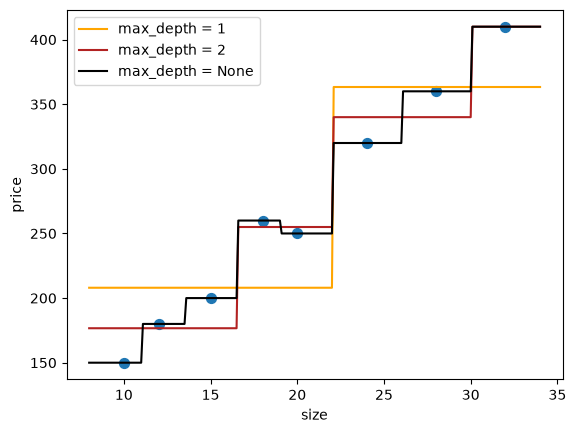

In [8]:
ax = houses.plot.scatter(x="size", y="price", s=50)
for depth, color in zip([1, 2, None], ["orange", "firebrick", "black"]):
    model = DecisionTreeRegressor(max_depth=depth).fit(X, y)
    ax.plot(sizes["size"], model.predict(sizes), color=color, label=f"max_depth = {depth}")
ax.legend();

✅ **Checkpoint 2.** (a) In the depth-2 plot, the right child of the root has `samples = 3` and
`value ≈ 363.3`. Which three houses are these, and what is its `squared_error` telling you? (b) The unlimited
tree has training RMSE 0. Is it the best tree? What would its prediction be for a house of size 22.5, and what
is it really based on? (c) In one sentence: what does increasing `max_depth` do to the regression function, and
what is the risk?

**Answer:** (a) The houses with size > 22: sizes 24, 28 and 32 (prices 320, 360, 410), mean 363.3. Its `squared_error`
(≈ 1,355.6) is the mean squared gap of those three prices from 363.3; it is far below the root's 7,248, which
is why the split was worth making, and above zero, which is why the tree keeps splitting if allowed. (b) No.
With eight leaves the tree has simply memorized the eight prices; for 22.5 it predicts **320**, the price of the
single size-24 house in that leaf — one observation, no averaging, so a noisy guess. Zero training error is a
warning sign, not a trophy. (c) More depth means more leaves and narrower steps, so the staircase follows the
training points ever more closely; the risk is **overfitting** — fitting the noise in these eight prices and
predicting new houses worse. Section 5 shows where the sweet spot is.

---
## 3. Training, validation and test data

Three sets of rows, three jobs:

| set | what it is used for | who may look at the prices |
|---|---|---|
| **training data** | fitting the model: `.fit(X_train, y_train)` | the model, during fitting |
| **validation data** | *choosing* between models and settings: fit on training rows, score on these | you, repeatedly, while deciding |
| **test data** | one final, honest report of the chosen model's error | nobody, until the very end — then once |

The test set must stay sealed while you decide. If you compare twenty models on the test set and pick the best,
its test error is no longer an honest estimate: you have used the test prices to make a choice, which is a
mild form of fitting to them. The validation set exists so you can make all your choices *without* touching the
test set.

The pre-class reading used the **Bordeaux wine** data: 38 vintages, with the price known only for the years up
to 1980. Those 27 vintages are the training data; the 11 later vintages, whose prices we do *not* have, are the
test data in the truest sense — we will have to predict them blind. The target is `log(price)`, the features
`win` (winter rainfall, mm) and `summer` (summer temperature, °C).

In [9]:
bordeaux = pd.read_csv("https://dlsun.github.io/pods/data/bordeaux.csv", index_col="year")
bordeaux_train = bordeaux.loc[:1980].copy()
bordeaux_train["log(price)"] = np.log(bordeaux_train["price"])
bordeaux_test = bordeaux.loc[1981:]

print("training vintages:", len(bordeaux_train), "  test vintages:", len(bordeaux_test),
      "  test prices known:", bordeaux_test["price"].notna().sum())
bordeaux_train.head()

training vintages: 27   test vintages: 11   test prices known: 0


,price,summer,har,sep,win,age,log(price)
year,,,,,,,
1952,37.0,17.1,160,14.3,600,40,3.610918
1953,63.0,16.7,80,17.3,690,39,4.143135
1955,45.0,17.1,130,16.8,502,37,3.806662
1957,22.0,16.1,110,16.2,420,35,3.091042
1958,18.0,16.4,187,19.1,582,34,2.890372


To estimate how a model will do on the unknown test vintages, **carve a validation set out of the training
data**. The reading did this with `.sample(frac=0.5)`; `train_test_split` does the same with a `random_state`
so everyone gets the same split. Half and half, as in the reading.

In [10]:
X_wine = bordeaux_train[["win", "summer"]]
y_wine = bordeaux_train["log(price)"]
X_train, X_val, y_train, y_val = train_test_split(X_wine, y_wine, test_size=0.5, random_state=5544)
print("training rows:", len(X_train), "  validation rows:", len(X_val))

training rows: 13   validation rows: 14


✅ **Checkpoint 3.** (a) Why can we not compute a *test* error for the vintages after 1980? (b) The validation
set was carved out of the 27 training vintages. In what sense does it "play the role" of test data, and what
makes it different from the real test set? (c) After you have chosen a model using the validation set, which
rows should the *final* model be fitted on?

**Answer:** (a) Their prices are missing (`NaN`), so there is nothing to compare predictions against. (b) The model is
fitted without seeing the validation prices, so when it predicts them it is predicting *unseen* rows — exactly
the situation it will face on the test vintages. The difference: the validation prices *are* known, so the
error can be computed, and the validation rows come from the same years as the training rows rather than from
the future. (c) **All 27 training vintages.** The validation split was only a device for choosing; once the
choice is made, refit the chosen model on every row whose price is known (the reading's "important note").

---
## 4. Training error vs validation error

**Training error** is the error on the rows the model was fitted on. **Validation error** is the error on rows
it was *not* fitted on. Both are computed the same way — `root_mean_squared_error(actual, predicted)` — on
different rows.

The pre-class reading's model: a 5-nearest-neighbor regressor on `win` and `summer`, with the two features
scaled first because KNN measures distances (Topic 9.1, section 5). `make_pipeline` chains the scaler and the
model; section 8 says more about why.

In [11]:
knn5 = make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=5))
knn5.fit(X_train, y_train)                          # fitted on the 13 training vintages only

rmse_train = root_mean_squared_error(y_train, knn5.predict(X_train))
rmse_val   = root_mean_squared_error(y_val,   knn5.predict(X_val))
print(f"training RMSE   = {rmse_train:.3f}  (log price units)")
print(f"validation RMSE = {rmse_val:.3f}")

training RMSE   = 0.514  (log price units)
validation RMSE = 0.502


Now the same comparison for three values of *k*. Watch the 1-nearest-neighbor row.

In [12]:
rows = []
for k in [1, 5, 13]:
    model = make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=k)).fit(X_train, y_train)
    rows.append({"k": k,
                 "training RMSE":   root_mean_squared_error(y_train, model.predict(X_train)),
                 "validation RMSE": root_mean_squared_error(y_val,   model.predict(X_val))})
pd.DataFrame(rows).round(3)

,k,training RMSE,validation RMSE
0,1,0.000,0.606
1,5,0.514,0.502
2,13,0.713,0.508


The 1-NN model has a training RMSE of **exactly 0**: every training vintage is its own nearest neighbor, so it
"predicts" its own price. Its validation RMSE is the worst of the three. Training error alone would have
crowned the worst model. That is the whole argument for validation error in one row.

Two honest footnotes. First, the training and validation RMSEs of the 5-NN model are close, and here the
validation one even comes out slightly *lower*; with 13 training and 14 validation vintages a single split is
noisy, and a different `random_state` gives different numbers. That noise is the problem the next section
fixes. Second, the validation error is usually *higher* than the training error — predicting unseen rows is
harder — but "usually" is not "always", especially with tiny data.

✅ **Checkpoint 4.** (a) Why is the 1-NN training RMSE exactly 0, and would the same happen for a decision tree
with `max_depth=None`? (b) Explain in one sentence why training error cannot be used to choose *k*. (c) What is
the weakness of the validation RMSE computed from one 50/50 split?

**Answer:** (a) For a training vintage, the closest training vintage is itself (distance 0), so 1-NN returns its own
log price and the error is 0. Yes: an unlimited tree puts each distinct training row in its own leaf and
reproduces every training price, so its training RMSE is also 0 (section 2). (b) Training error always favours
the most flexible setting — smaller *k*, deeper trees — because flexibility lets a model memorize, and
memorizing is not predicting. (c) It depends on which rows happened to land in each half: with 27 rows the
estimate swings with the `random_state`, and the model was fitted on only half the data, so it is also a
pessimistic estimate of the model fitted on all 27.

---
## 5. K-fold cross-validation, step by step

One validation split wastes half the data and gives a noisy answer. **K-fold cross-validation** fixes both:

1. **Partition** the rows into K roughly equal **folds**.
2. For fold 1: **hold it out**, fit a *fresh* model on the other K − 1 folds, compute the error on fold 1.
3. **Repeat** for folds 2, …, K. Every row is held out exactly once, and every model is scored only on rows it
   never saw.
4. **Summarize:** average the K validation errors. The average is the cross-validation estimate of the error on
   new data; the spread of the K values shows how noisy that estimate is.

> ⚠️ **Two different k's.** The *k* in **k-nearest neighbors** (`n_neighbors`) is how many training rows are
> averaged for one prediction: a setting of the *model*. The *K* in **K-fold cross-validation** (`n_splits`) is
> how many pieces the data is cut into: a setting of the *evaluation*. They have nothing to do with each other;
> you can cross-validate a 3-nearest-neighbor model with 4 folds, which is exactly what the next cell does.
> This notebook writes the folds one as a capital K.

Back to the eight houses so that every fold can be seen. `KFold(n_splits=4, shuffle=True, random_state=5544)`
describes the partition; `kf.split(X)` yields, for each fold, the row positions of the training rows and of
the validation rows.

🎬 *Watch it on the page:* [Cross-validation in motion: 3-nearest neighbors, K = 4 folds, shuffled](https://gato365.github.io/gsb5544_instructor_learn_prep/week_9/algorithms.html#cv&model=knn&k=3&folds=4&shuffle=1) — press **Play**, or step through with → and ←.

In [13]:
kf = KFold(n_splits=4, shuffle=True, random_state=5544)

val_scores, train_scores = [], []
for i, (train_idx, val_idx) in enumerate(kf.split(X), start=1):
    model = KNeighborsRegressor(n_neighbors=3)                 # a fresh, unfitted model every iteration
    model.fit(X.iloc[train_idx], y.iloc[train_idx])           # fit on the other 3 folds (6 houses)
    pred = model.predict(X.iloc[val_idx])                     # predict the 2 held-out houses
    rmse_val   = root_mean_squared_error(y.iloc[val_idx], pred)
    rmse_train = root_mean_squared_error(y.iloc[train_idx], model.predict(X.iloc[train_idx]))
    val_scores.append(rmse_val); train_scores.append(rmse_train)
    print(f"fold {i}: validation houses {(val_idx + 1).tolist()}, training houses {(train_idx + 1).tolist()}   "
          f"training RMSE {rmse_train:5.2f}   validation RMSE {rmse_val:5.2f}")

print(f"\nmean training RMSE   = {np.mean(train_scores):.2f}")
print(f"mean validation RMSE = {np.mean(val_scores):.2f}   <- the cross-validation estimate")

fold 1: validation houses [6, 7], training houses [1, 2, 3, 4, 5, 8]   training RMSE 45.28   validation RMSE 38.87
fold 2: validation houses [2, 5], training houses [1, 3, 4, 6, 7, 8]   training RMSE 29.12   validation RMSE 17.95
fold 3: validation houses [1, 3], training houses [2, 4, 5, 6, 7, 8]   training RMSE 32.66   validation RMSE 60.42
fold 4: validation houses [4, 8], training houses [1, 2, 3, 5, 6, 7]   training RMSE 25.53   validation RMSE 79.06

mean training RMSE   = 33.15
mean validation RMSE = 49.07   <- the cross-validation estimate


Compare with the page: fold 1 holds out houses 6 and 7, fold 2 houses 2 and 5, fold 3 houses 1 and 3, fold 4
houses 4 and 8; the four validation RMSEs are 38.87, 17.95, 60.42 and 79.06 and their mean is **49.07**. Four
models were fitted. None of them is the final model: once the comparison is done, the chosen model is refitted
on all eight houses.

**Why `shuffle=True`?** `KFold` cuts the rows in their current order unless told otherwise, and these houses are
sorted by size. Unshuffled folds hold out the two smallest or the two largest houses together, so the model
has to *extrapolate*, and the errors say more about the row order than about the model.

🎬 *Watch it on the page:* [The same, without shuffling: folds of consecutive rows](https://gato365.github.io/gsb5544_instructor_learn_prep/week_9/algorithms.html#cv&model=knn&k=3&folds=4&shuffle=0) — press **Play**, or step through with → and ←.

In [14]:
for K in [4, 2]:
    kf_plain = KFold(n_splits=K)                                   # shuffle=False: consecutive rows
    scores = []
    for train_idx, val_idx in kf_plain.split(X):
        model = KNeighborsRegressor(n_neighbors=3).fit(X.iloc[train_idx], y.iloc[train_idx])
        scores.append(root_mean_squared_error(y.iloc[val_idx], model.predict(X.iloc[val_idx])))
        print(f"K={K}: validation houses {(val_idx + 1).tolist()}  RMSE {scores[-1]:6.2f}")
    print(f"K={K}, no shuffle: mean validation RMSE = {np.mean(scores):.2f}\n")

K=4: validation houses [1, 2]  RMSE  73.22
K=4: validation houses [3, 4]  RMSE   8.50
K=4: validation houses [5, 6]  RMSE  30.73
K=4: validation houses [7, 8]  RMSE 111.18
K=4, no shuffle: mean validation RMSE = 55.91

K=2: validation houses [1, 2, 3, 4]  RMSE 119.48
K=2: validation houses [5, 6, 7, 8]  RMSE 135.01
K=2, no shuffle: mean validation RMSE = 127.24



✅ **Checkpoint 5.** (a) With K = 4 on eight houses, how many houses is each model fitted on, how many is it
scored on, and how many models are fitted in total? (b) Which of these is a *k* and which is a *K*:
`KNeighborsRegressor(n_neighbors=3)`, `KFold(n_splits=4)`? (c) K = 8 here would be *leave-one-out* cross-
validation. What is one advantage and one cost of using more folds?

**Answer:** (a) Fitted on 6, scored on 2, four models in total (plus the final refit on all 8). (b) `n_neighbors=3` is the
model's *k*; `n_splits=4` is the cross-validation *K*. (c) More folds → each training set is larger (7 of 8
houses with K = 8), so the fitted models are closer to the final model and the estimate is less pessimistic.
Costs: K fits instead of a few (slow on big data or slow models), and the K training sets overlap heavily, so
the K scores are highly correlated and their average is more variable. The reading settles on 5 or 10 folds
in practice.

---
## 6. One call: `cross_val_score` and `cross_validate`

The loop above is what `cross_val_score` does internally. Its arguments:

| argument | meaning |
|---|---|
| the model (or pipeline) | an *unfitted* estimator; it is cloned and fitted once per fold |
| `X`, `y` | all the rows you want cross-validated (the training data, never the test set) |
| `cv=` | the folds: a `KFold` object, or an integer *K* (shorthand for `KFold(K)` with **no** shuffle) |
| `scoring=` | the name of a scorer; for RMSE use `"neg_root_mean_squared_error"` |

It **returns an array of K scores**, one per fold. They are **negative**: scikit-learn insists that a score be
something to *maximize*, so errors are reported with a minus sign (`"neg_..."`). Negate to get RMSEs; average
for the cross-validation estimate. The reading used `"neg_mean_squared_error"` and then `np.sqrt(-scores)`;
`"neg_root_mean_squared_error"` skips the square root step.

In [15]:
scores = cross_val_score(KNeighborsRegressor(n_neighbors=3), X, y,
                         cv=kf,                                     # the same shuffled 4 folds as above
                         scoring="neg_root_mean_squared_error")
print("scores as returned:", scores.round(2))
print("validation RMSE per fold:", (-scores).round(2))
print("cross-validation estimate:", round(-scores.mean(), 2))

scores as returned: [-38.87 -17.95 -60.42 -79.06]
validation RMSE per fold: [38.87 17.95 60.42 79.06]
cross-validation estimate: 49.07


`cross_validate` is the same call with more detail: a dictionary of arrays, including fit times and — with
`return_train_score=True` — the training score of each fold, so you can see training and validation error
side by side exactly as the page's table shows them.

In [16]:
cv_results = cross_validate(KNeighborsRegressor(n_neighbors=3), X, y, cv=kf,
                            scoring="neg_root_mean_squared_error", return_train_score=True)
table = pd.DataFrame({"training RMSE": -cv_results["train_score"],
                      "validation RMSE": -cv_results["test_score"]}, index=[f"fold {i}" for i in range(1, 5)])
table.loc["mean"] = table.mean()
table.round(2)

,training RMSE,validation RMSE
fold 1,45.28,38.87
fold 2,29.12,17.95
fold 3,32.66,60.42
fold 4,25.53,79.06
mean,33.15,49.07


✅ **Checkpoint 6.** (a) `cross_val_score` returned four numbers. Why four, and why negative? (b) What is the
difference between `cv=kf` and `cv=4` here, and which would you use on data sorted by size? (c) The key
`"test_score"` in `cross_validate`'s output: is it computed on the test set?

**Answer:** (a) One per fold (K = 4); negative because scikit-learn treats every score as "higher is better", so an error is
returned as its negative — `-scores` are the RMSEs. (b) `cv=kf` uses our `KFold(4, shuffle=True,
random_state=5544)`; `cv=4` means `KFold(4)` with *no* shuffle, consecutive rows. On data sorted by size use the
shuffled `KFold`. (c) No — scikit-learn calls the held-out fold the "test" fold, but it is our *validation*
fold. The real test set never enters `cross_validate`.

---
## 7. Choosing a model and its settings, with the test set sealed

Cross-validation earns its keep when there are candidates to compare: linear regression vs KNN vs a tree, and
within KNN every *k*, within the tree every depth. The protocol:

1. **Split off a test set and seal it.** `train_test_split` once, at the start.
2. **Cross-validate every candidate on the training set** with the *same* folds, so the averages are comparable.
3. **Pick** the candidate with the smallest mean validation RMSE.
4. **Refit** the winner on the whole training set and **report its test RMSE once.**

The Advertising data from Topics 8.2 and 9.1 (200 markets; `TV` and `radio` budgets → `sales`) is big enough
for this to be realistic. Same split as Topic 9.1: 150 training markets, 50 sealed test markets.

In [17]:
ads = pd.read_csv("https://www.statlearning.com/s/Advertising.csv", index_col=0)
X_ads = ads[["TV", "radio"]]
y_ads = ads["sales"]
X_tr, X_te, y_tr, y_te = train_test_split(X_ads, y_ads, test_size=0.25, random_state=5544)
kf5 = KFold(n_splits=5, shuffle=True, random_state=5544)     # 5 folds of 30 markets; reused for every candidate
print("training markets:", len(X_tr), "  sealed test markets:", len(X_te))

training markets: 150   sealed test markets: 50


**Every k from 1 to 20.** KNN has two features now, so the scaler goes in a pipeline (section 8). For each *k*,
`cross_validate` fits 5 models and returns 5 training and 5 validation scores; we keep the means.

best k by cross-validation: 2   mean validation RMSE: 0.878


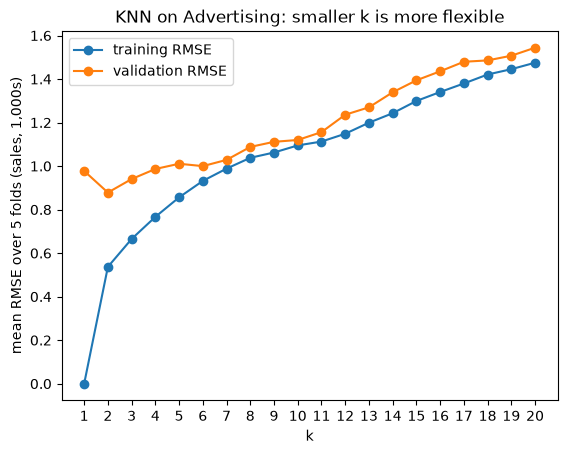

In [18]:
knn_rows = []
for k in range(1, 21):
    pipe = make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=k))
    res = cross_validate(pipe, X_tr, y_tr, cv=kf5, scoring="neg_root_mean_squared_error", return_train_score=True)
    knn_rows.append({"k": k, "training RMSE": -res["train_score"].mean(), "validation RMSE": -res["test_score"].mean()})
knn_cv = pd.DataFrame(knn_rows).set_index("k")

ax = knn_cv.plot(marker="o", xticks=range(1, 21), ylabel="mean RMSE over 5 folds (sales, 1,000s)")
ax.set_title("KNN on Advertising: smaller k is more flexible");
best_k = knn_cv["validation RMSE"].idxmin()
print("best k by cross-validation:", best_k, "  mean validation RMSE:", round(knn_cv.loc[best_k, "validation RMSE"], 3))

**Every depth from 1 to 10** for the tree, and the line (which has nothing to tune) once.

best max_depth by cross-validation: 7   mean validation RMSE: 0.928
linear regression mean validation RMSE: 1.732


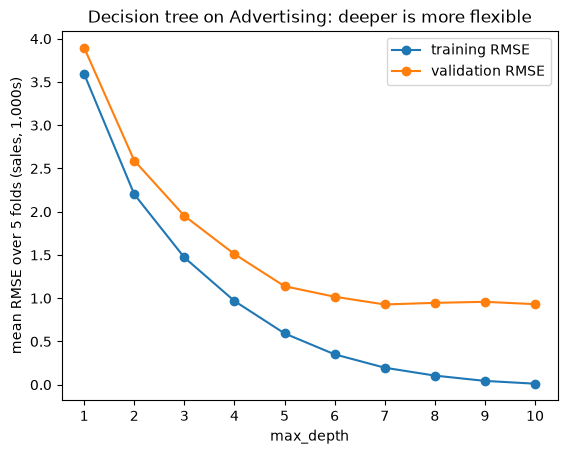

In [19]:
tree_rows = []
for depth in range(1, 11):
    tree = DecisionTreeRegressor(max_depth=depth, random_state=5544)
    res = cross_validate(tree, X_tr, y_tr, cv=kf5, scoring="neg_root_mean_squared_error", return_train_score=True)
    tree_rows.append({"max_depth": depth, "training RMSE": -res["train_score"].mean(), "validation RMSE": -res["test_score"].mean()})
tree_cv = pd.DataFrame(tree_rows).set_index("max_depth")

ax = tree_cv.plot(marker="o", xticks=range(1, 11), ylabel="mean RMSE over 5 folds (sales, 1,000s)")
ax.set_title("Decision tree on Advertising: deeper is more flexible");
best_depth = tree_cv["validation RMSE"].idxmin()

linear_cv = -cross_val_score(LinearRegression(), X_tr, y_tr, cv=kf5, scoring="neg_root_mean_squared_error").mean()
print("best max_depth by cross-validation:", best_depth, "  mean validation RMSE:", round(tree_cv.loc[best_depth, "validation RMSE"], 3))
print("linear regression mean validation RMSE:", round(linear_cv, 3))

Read the two plots the same way: the **training** curve falls as the model gets more flexible (smaller *k*,
deeper tree) all the way to 0 — it always does, so it cannot choose anything. The **validation** curve has a
minimum, and that minimum is the choice.

**Step 4: unseal the test set, once.** Refit each family's winner on all 150 training markets and report the
test RMSE. This is the only time `X_te` and `y_te` appear.

In [20]:
finalists = {
    "linear regression":              LinearRegression(),
    f"{best_k}-nearest neighbors (scaled)": make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=best_k)),
    f"tree, max_depth={best_depth}":   DecisionTreeRegressor(max_depth=best_depth, random_state=5544),
}
cv_estimate = {"linear regression": linear_cv,
               f"{best_k}-nearest neighbors (scaled)": knn_cv.loc[best_k, "validation RMSE"],
               f"tree, max_depth={best_depth}": tree_cv.loc[best_depth, "validation RMSE"]}
for name, model in finalists.items():
    model.fit(X_tr, y_tr)                                           # refit on ALL 150 training markets
    test_rmse = root_mean_squared_error(y_te, model.predict(X_te))   # the one and only look at the test set
    print(f"{name:32s} CV estimate {cv_estimate[name]:.3f}   test RMSE {test_rmse:.3f}")

linear regression                CV estimate 1.732   test RMSE 1.617
2-nearest neighbors (scaled)     CV estimate 0.878   test RMSE 0.811
tree, max_depth=7                CV estimate 0.928   test RMSE 1.396


✅ **Checkpoint 7.** (a) Which candidate wins, and did the test RMSE agree with the cross-validation ranking?
(b) Why was the test set not used to choose *k* or the depth, when it is right there? (c) A classmate reports
"my tree has training RMSE 0.01 at depth 10, so depth 10 is best." Respond in two sentences using the tree plot.

**Answer:** (a) The scaled **2-nearest-neighbor** model: CV estimate ≈ 0.88, test RMSE ≈ 0.81 — the best of the three on
both; the tree (depth 7: CV ≈ 0.93, test ≈ 1.40) and the line (CV ≈ 1.73, test ≈ 1.62) follow in the same
order. The CV numbers are estimates, not promises — the tree's test RMSE came out noticeably worse than its CV
estimate — but the *ranking* held, which is what we asked of them. (b) Choosing on the test set would make the
test error an optimistic, used-up number: with twenty values of *k* tried, the smallest test error is partly
luck, and there would be nothing left to report honestly. The validation folds absorb the choosing so the test
set can keep its one job. (c) Training RMSE always falls with depth, so it rewards depth 10 no matter what;
the validation curve, which measures prediction on markets the tree did not see, bottoms out around depth 7
and the deeper trees are no better. Depth 10 is memorizing, not predicting.

---
## 8. Pipelines and leakage

> 📦 **Definition — Pipeline.** A scikit-learn **Pipeline combines preprocessing steps and a model into one
> object** with a single `.fit()` and a single `.predict()`. On `.fit(X_train, y_train)` each preprocessing step
> learns what it needs *from the training rows only* (a scaler: the mean and standard deviation; a one-hot
> encoder: the categories), transforms them and passes them on; the model at the end is fitted on the result.
> On `.predict(X_new)` the *same fitted* preprocessing is applied — nothing is re-learned from the new rows.
> A pipeline is not a prediction algorithm; it makes sure the right preprocessing always travels with the model.

Now the reason pipelines belong in *this* topic. Cross-validation only tells the truth if every fold's model
sees **nothing** from its validation rows. Scaling is fitting: `StandardScaler().fit(X)` computes a mean and a
standard deviation from whatever rows it is given. So:

- ❌ **Scale first, cross-validate after:** the scaler saw all 27 wines, including each fold's validation
  rows. Their values leaked into the mean and standard deviation that the training rows were scaled with.
- ✅ **Cross-validate the pipeline:** `cross_val_score` fits the *whole pipeline* on each fold's training rows,
  so the scaler is refitted K times on training rows only — the same thing that will happen when truly new
  data arrives.

The difference in the number is usually small (here it is), but the procedure is what matters: the leaky
version answers a question nobody asked — "how well does the model do when it has peeked at the validation
rows' spread?" — and with other preprocessing (imputing missing values, selecting features, encoding the
target) the leak can be large.

In [21]:
kf4 = KFold(n_splits=4, shuffle=True, random_state=5544)

# WRONG: the scaler learns the mean and sd of all 27 vintages, validation rows included
X_scaled = pd.DataFrame(StandardScaler().fit_transform(X_wine), columns=X_wine.columns, index=X_wine.index)
leaky = -cross_val_score(KNeighborsRegressor(n_neighbors=5), X_scaled, y_wine, cv=kf4,
                         scoring="neg_root_mean_squared_error").mean()

# RIGHT: the pipeline is refitted inside every fold, scaler included
pipe = make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=5))
clean = -cross_val_score(pipe, X_wine, y_wine, cv=kf4, scoring="neg_root_mean_squared_error").mean()

print(f"scale everything, then cross-validate: {leaky:.4f}   (leaks the validation rows into the scaler)")
print(f"cross-validate the pipeline:           {clean:.4f}   (scaler refitted on training rows in each fold)")

scale everything, then cross-validate: 0.5308   (leaks the validation rows into the scaler)
cross-validate the pipeline:           0.5372   (scaler refitted on training rows in each fold)


This is the reading's `cross_val_score(pipeline, ...)` call with our shuffled folds and RMSE scoring. The
reading's `neg_mean_squared_error` route gives the same mean once you take `np.sqrt(-scores)` fold by fold.

Finally, the loop of section 7 exists as a function: `GridSearchCV` takes a pipeline, a grid of settings and a
`cv`, cross-validates every setting, and keeps the best — refitted on all the training rows. The step name
`kneighborsregressor__n_neighbors` means "the `n_neighbors` argument of the `kneighborsregressor` step".

In [22]:
from sklearn.model_selection import GridSearchCV

search = GridSearchCV(make_pipeline(StandardScaler(), KNeighborsRegressor()),
                      param_grid={"kneighborsregressor__n_neighbors": range(1, 21)},
                      cv=kf5, scoring="neg_root_mean_squared_error")
search.fit(X_tr, y_tr)                       # cross-validates all 20 settings, then refits the best on all 150 rows
print("best k:", search.best_params_, "  mean validation RMSE:", round(-search.best_score_, 3))
print("test RMSE of the refitted winner:", round(root_mean_squared_error(y_te, search.predict(X_te)), 3))

best k: {'kneighborsregressor__n_neighbors': 2}   mean validation RMSE: 0.878
test RMSE of the refitted winner: 0.811


✅ **Checkpoint 8.** (a) In the "wrong" version, what exactly did the model learn from the validation rows?
(b) Why does handing `cross_val_score` a pipeline fix it, in one sentence about *when* the scaler is fitted?
(c) `GridSearchCV.fit` fitted how many KNN models in total, and which one does `search.predict` use?

**Answer:** (a) Their contribution to the mean and standard deviation of `win` and `summer`: the training rows were put on
a scale that already knew how spread out the validation rows were. (b) Inside each fold the pipeline — scaler
first — is fitted on that fold's training rows only, so the scaler never sees the held-out rows until it
transforms them for prediction. (c) 20 settings × 5 folds = 100 cross-validation fits, plus one final fit of
the best setting (k = 2) on all 150 training rows; `search.predict` uses that final refitted model.

---
## 9. Review questions

Short answers; a sentence or a number each.

**Q1.** For each of `LinearRegression()`, `KNeighborsRegressor(n_neighbors=3)` and
`DecisionTreeRegressor(max_depth=2)`: what does `.fit` compute, and what does `.predict` do with a new row?

**Answer:** Line: `.fit` finds the intercept and slope with the smallest SSE; `.predict` evaluates intercept + slope × size.
KNN: `.fit` stores the rows; `.predict` finds the 3 nearest training sizes and averages their prices. Tree:
`.fit` chooses the SSE-minimizing thresholds and each leaf's mean; `.predict` follows the yes/no questions to a
leaf and returns its mean.

**Q2.** A node in `plot_tree` reads `size <= 16.5, squared_error = 1736.0, samples = 5, value = 208.0`. Explain
each number, and compute the node's SSE.

**Answer:** The node asks whether size ≤ 16.5; 5 training houses reach it; their mean price is 208.0 (the prediction if the
node were a leaf); 1,736.0 is the mean squared gap of those five prices from 208.0. SSE = 1,736 × 5 = **8,680**.

**Q3.** Training data, validation data, test data: one job each, and the rule about when the test set may be
touched.

**Answer:** Training: fit the model. Validation: choose between models and settings (repeatedly). Test: report the chosen
model's error, **once, after every choice has been made** — never to pick a model.

**Q4.** Why is a training RMSE of 0 not good news? Give the two models from today that achieve it.

**Answer:** It means the model has reproduced the training prices exactly — memorized them, noise included — which says
nothing about new rows and usually predicts them worse. 1-nearest neighbor and a decision tree with
`max_depth=None` (one house per leaf) both score 0 on training data.

**Q5.** Describe 5-fold cross-validation of a 10-nearest-neighbor model on 150 rows: how many folds, how many
rows per fold, how many models are fitted, on how many rows each, and what is reported. Which number is *k*
and which is *K*?

**Answer:** Five folds of 30 rows. Five models, each fitted on 120 rows and scored on the 30 held-out rows; the five
validation RMSEs are averaged into one estimate (and their spread shows the noise). k = 10 is the model's
neighbors; K = 5 is the number of folds.

**Q6.** `cross_val_score(model, X, y, cv=5, scoring="neg_root_mean_squared_error")` returns
`[-0.9, -1.1, -0.8, -1.0, -1.2]`. What is the cross-validation estimate of RMSE, and why the minus signs?
Which rows should `X` and `y` be?

**Answer:** Negate and average: (0.9 + 1.1 + 0.8 + 1.0 + 1.2) / 5 = **1.0**. The signs are negative because scikit-learn
treats scores as "higher is better" and so reports errors as negatives. `X` and `y` must be the *training*
data — the test set stays out of cross-validation.

**Q7.** On the Advertising data the training RMSE of the tree kept falling to depth 10 while the validation
RMSE stopped improving around depth 7. Which depth do you choose, and what do you call the gap between the two
curves at depth 10?

**Answer:** Depth 7 (the smallest mean validation RMSE); the gap at depth 10 — training error near 0, validation error no
better than at 7 — is **overfitting**: the extra leaves fit noise in the training markets.

**Q8.** A classmate scales all the columns with `StandardScaler().fit_transform(X)` and *then* runs
`cross_val_score` on a KNN model. What is wrong, how do you fix it, and why does the fix work?

**Answer:** The scaler was fitted on every row, so each fold's validation rows leaked into the mean and standard deviation
used to scale that fold's training rows. Fix: `cross_val_score(make_pipeline(StandardScaler(),
KNeighborsRegressor(...)), X, y, cv=...)`. It works because the pipeline is refitted inside each fold, so the
scaler learns from the training rows only and merely *applies* that scaling to the held-out rows.

---
## The lines to keep

| | |
|---|---|
| **Seal the test set** | `X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, random_state=5544)` — then do not touch `X_te`, `y_te` until the end |
| **Folds** | `kf = KFold(n_splits=5, shuffle=True, random_state=5544)` — K folds; shuffle unless the row order is already random |
| **The loop** | `for train_idx, val_idx in kf.split(X_tr):` fresh `model` → `.fit(X_tr.iloc[train_idx], y_tr.iloc[train_idx])` → `root_mean_squared_error(y_tr.iloc[val_idx], model.predict(X_tr.iloc[val_idx]))` → average |
| **One call** | `-cross_val_score(model, X_tr, y_tr, cv=kf, scoring="neg_root_mean_squared_error").mean()`; `cross_validate(..., return_train_score=True)` for training scores too |
| **Choose** | smallest mean validation RMSE across candidates (`k`, `max_depth`, model families), *same folds for all* |
| **Finish** | refit the winner on all of `X_tr`, `y_tr`; report `root_mean_squared_error(y_te, model.predict(X_te))` once |
| **Pipelines** | `make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=k))` goes *into* `cross_val_score` so preprocessing is refitted inside every fold — no leakage |
| **Two k's** | `n_neighbors` = how many neighbors (model); `n_splits` = how many folds (evaluation) |

Course site: [https://gato365.github.io/gsb5544_instructor_learn_prep/](https://gato365.github.io/gsb5544_instructor_learn_prep/).